# Model · Huấn luyện và đánh giá mô hình bệnh tim mạch




#### Đọc dữ liệu đã làm sạch


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

data_path = "File_train.csv"
cardio_data = pd.read_csv(data_path)

# Phần 1. Chuẩn bị dữ liệu cho mô hình

#### 1.1. Chọn cột đầu vào và mã hóa

`X` chứa 11 đặc điểm sức khỏe và sinh hoạt. `y` chứa nhãn cần dự đoán. Cột `id` chỉ dùng để phân biệt các bản ghi.

In [2]:
feature_columns = [
    "age", "gender", "height", "weight", "ap_hi", "ap_lo",
    "cholesterol", "gluc", "smoke", "alco"
]

X = cardio_data[feature_columns].copy()
y = cardio_data["cardio"].copy()

`get_dummies` chuyển từng nhóm thành cột 0/1. Ví dụ, `cholesterol_3 = 1` nghĩa là người đó thuộc mức 3. Tham số `drop_first=True` giữ mức đầu làm nhóm đối chiếu.

In [3]:
columns_to_encode = ["gender", "cholesterol", "gluc"]
X = pd.get_dummies(X, columns=columns_to_encode, drop_first=True, dtype=int)

print("Kích thước ma trận đặc trưng sau khi mã hóa:", X.shape)

encoded_column_names = X.columns.tolist()
print("Danh sách cột sau khi mã hóa:", encoded_column_names)
display(X.head())

Kích thước ma trận đặc trưng sau khi mã hóa: (59187, 12)
Danh sách cột sau khi mã hóa: ['age', 'height', 'weight', 'ap_hi', 'ap_lo', 'smoke', 'alco', 'gender_2', 'cholesterol_2', 'cholesterol_3', 'gluc_2', 'gluc_3']


,age,height,weight,ap_hi,ap_lo,smoke,alco,gender_2,cholesterol_2,cholesterol_3,gluc_2,gluc_3
0,50,168,62.0,110,80,0,0,1,0,0,0,0
1,55,156,85.0,140,90,0,0,0,0,1,0,0
2,52,165,64.0,130,70,0,0,0,0,1,0,0
3,48,169,82.0,150,100,0,0,1,0,0,0,0
4,60,151,67.0,120,80,0,0,0,1,0,1,0


#### 1.2. Chia dữ liệu thành hai tập

Dùng 80% để học và 20% để kiểm tra. `stratify=y` giúp hai tập có tỷ lệ người có bệnh gần nhau.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

**Chuẩn hóa cho Logistic Regression.** Tính trung bình và độ lệch chuẩn trên tập huấn luyện, rồi dùng cùng các giá trị đó để biến đổi tập kiểm tra.

In [5]:
standard_scaler = StandardScaler()

X_train_scaled = standard_scaler.fit_transform(X_train)
X_test_scaled = standard_scaler.transform(X_test)

**Kiểm tra lại** số hàng và tỷ lệ hai nhãn sau khi chia.

In [6]:
print("Kích thước tập huấn luyện (X_train):", X_train.shape)
print("Số mẫu tập huấn luyện (Train):", len(y_train))
print("Kích thước tập kiểm tra (X_test):", X_test.shape)
print("Số mẫu tập kiểm tra (Test):", len(y_test))

train_percentage = y_train.value_counts(normalize=True) * 100
train_percentage = train_percentage.round(2)
print("Tỷ lệ phân bố cardio trong tập Train:\n", train_percentage.to_dict())

test_percentage = y_test.value_counts(normalize=True) * 100
test_percentage = test_percentage.round(2)
print("Tỷ lệ phân bố cardio trong tập Test:\n", test_percentage.to_dict())

Kích thước tập huấn luyện (X_train): (47349, 12)
Số mẫu tập huấn luyện (Train): 47349
Kích thước tập kiểm tra (X_test): (11838, 12)
Số mẫu tập kiểm tra (Test): 11838
Tỷ lệ phân bố cardio trong tập Train:
 {1: 51.03, 0: 48.97}
Tỷ lệ phân bố cardio trong tập Test:
 {1: 51.03, 0: 48.97}


# Phần 2. Huấn luyện và đánh giá

#### 2.1. Khởi tạo ba mô hình

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

models = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42),
}

**Huấn luyện và dự đoán.** Mỗi mô hình học trên cùng các hàng. `predict` trả về nhãn 0/1. `predict_proba` cho điểm xác suất thuộc nhóm 1 để tính ROC-AUC.

In [8]:
results = []
trained_models = {}

for model_name, model in models.items():
    if model_name == "Logistic Regression":
        model.fit(X_train_scaled, y_train)
        y_predicted = model.predict(X_test_scaled)
        probability_table = model.predict_proba(X_test_scaled)
        y_probability = probability_table[:, 1]
    else:
        model.fit(X_train, y_train)
        y_predicted = model.predict(X_test)
        probability_table = model.predict_proba(X_test)
        y_probability = probability_table[:, 1]

    trained_models[model_name] = model

    accuracy_value = round(accuracy_score(y_test, y_predicted), 3)
    precision_value = round(precision_score(y_test, y_predicted), 3)
    recall_value = round(recall_score(y_test, y_predicted), 3)
    f1_value = round(f1_score(y_test, y_predicted), 3)
    roc_auc_value = round(roc_auc_score(y_test, y_probability), 3)

    model_result = {
        "Model": model_name,
        "Accuracy": accuracy_value,
        "Precision": precision_value,
        "Recall": recall_value,
        "F1-score": f1_value,
        "ROC-AUC": roc_auc_value,
    }
    results.append(model_result)

**So sánh trên cùng tập kiểm tra.** Precision cho biết trong số người được dự đoán có bệnh, bao nhiêu người thực sự có bệnh. Recall cho biết mô hình tìm được bao nhiêu trong tổng số người có bệnh. F1 kết hợp hai chỉ số này.

In [9]:
results_table = pd.DataFrame(results)
results_table = results_table.sort_values("F1-score", ascending=False)

print("BẢNG TỔNG HỢP HIỆU NĂNG CÁC MÔ HÌNH TRÊN TẬP TEST:")
display(results_table)

best_row = results_table.iloc[0]
best_model_name = best_row["Model"]
best_model = trained_models[best_model_name]

print("\n--> Mô hình có F1-score cao nhất được lựa chọn: " + best_model_name)

BẢNG TỔNG HỢP HIỆU NĂNG CÁC MÔ HÌNH TRÊN TẬP TEST:


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
1,Decision Tree,0.722,0.759,0.668,0.711,0.785
0,Logistic Regression,0.718,0.748,0.676,0.710,0.782
2,Random Forest,0.720,0.754,0.671,0.710,0.790



--> Mô hình có F1-score cao nhất được lựa chọn: Decision Tree


#### 2.2. Mô hình được chọn sai ở đâu?

Dùng mô hình đứng đầu bảng F1 ở bước 2.1. Trong ma trận, hàng là nhãn thật và cột là nhãn dự đoán. Ô hàng 1, cột 0 đếm số người có bệnh mà mô hình bỏ sót.

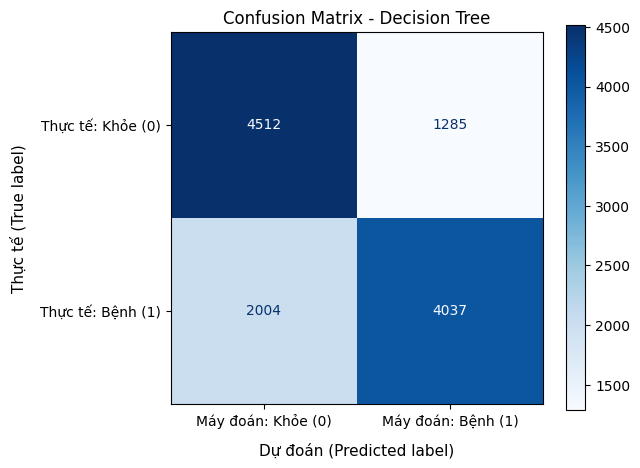

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

X_test_best = X_test
if best_model_name == "Logistic Regression":
    X_test_best = X_test_scaled

figure, axis = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_estimator(
    best_model, X_test_best, y_test, cmap='Blues', values_format='d', ax=axis)


axis.set_xticklabels(["Máy đoán: Khỏe (0)", "Máy đoán: Bệnh (1)"])
axis.set_yticklabels(["Thực tế: Khỏe (0)", "Thực tế: Bệnh (1)"])
axis.set_xlabel("Dự đoán (Predicted label)", fontsize=11, labelpad=10)
axis.set_ylabel("Thực tế (True label)", fontsize=11, labelpad=10)

axis.set_title("Confusion Matrix - " + best_model_name)
axis.grid(False)
plt.show()

**Đọc đường ROC.** Khi thay đổi ngưỡng dự đoán, tỷ lệ phát hiện người có bệnh và tỷ lệ báo nhầm cùng thay đổi. Đường cong càng gần góc trên bên trái thì khả năng phân biệt hai nhóm càng tốt.

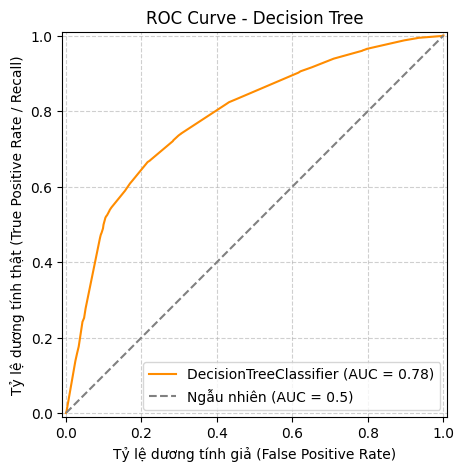

In [11]:
figure, axis = plt.subplots(figsize=(6, 5))
roc_display = RocCurveDisplay.from_estimator(best_model, X_test_best, y_test, ax=axis)
roc_display.line_.set_color('darkorange')
axis.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Ngẫu nhiên (AUC = 0.5)')
axis.set_title("ROC Curve - " + best_model_name)
axis.set_xlabel('Tỷ lệ dương tính giả (False Positive Rate)')
axis.set_ylabel('Tỷ lệ dương tính thật (True Positive Rate / Recall)')
axis.legend(loc='lower right')
axis.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Phần 3. Kết luận

Dữ liệu hiện tại có **59,187 người**, trong đó tập kiểm tra có **11,838 người**. Kết quả của ba mô hình được trình bày trong bảng so sánh ở phần 2.

Decision Tree và Random Forest cùng đạt F1-score **0,715** sau khi làm tròn ba chữ số thập phân. Theo cách sắp xếp giữ nguyên từ file gốc, Decision Tree đứng đầu bảng và được dùng để vẽ Confusion Matrix và ROC. Kết quả làm tròn này chưa cho thấy mô hình nào vượt trội rõ ràng.

